In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("krupadharamshi/fuelconsumption")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'fuelconsumption' dataset.
Path to dataset files: /kaggle/input/fuelconsumption


In [ ]:
import os
import pandas as pd

# List files in the downloaded path to identify the CSV file
file_list = os.listdir(path)
print(f"Files in the dataset directory: {file_list}")

# Assuming the CSV file is named 'FuelConsumptionCo2.csv' or similar
# We'll try to find a .csv file in the directory
csv_file = None
for f in file_list:
    if f.endswith('.csv'):
        csv_file = os.path.join(path, f)
        break

if csv_file:
    df = pd.read_csv(csv_file)
    print(f"Loaded dataset from: {csv_file}")
    display(df.head())
else:
    print("No CSV file found in the dataset directory.")

Files in the dataset directory: ['FuelConsumption (1).csv']
Loaded dataset from: /kaggle/input/fuelconsumption/FuelConsumption (1).csv


,Year,MAKE,MODEL,VEHICLE CLASS,ENGINE SIZE,CYLINDERS,TRANSMISSION,FUEL,FUEL CONSUMPTION,COEMISSIONS
0,2000,ACURA,1.6EL,COMPACT,1.6,4,A4,X,10.5,216
1,2000,ACURA,1.6EL,COMPACT,1.6,4,M5,X,9.8,205
2,2000,ACURA,3.2TL,MID-SIZE,3.2,6,AS5,Z,13.7,265
3,2000,ACURA,3.5RL,MID-SIZE,3.5,6,A4,Z,15.0,301
4,2000,ACURA,INTEGRA,SUBCOMPACT,1.8,4,A4,X,11.4,230


### Data Overview and Cleaning

In [ ]:
# Check shape and data types
print("\nDataset Info:")
df.info()


Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 639 entries, 0 to 638
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Year              639 non-null    int64  
 1   MAKE              639 non-null    object 
 2   MODEL             639 non-null    object 
 3   VEHICLE CLASS     639 non-null    object 
 4   ENGINE SIZE       639 non-null    float64
 5   CYLINDERS         639 non-null    int64  
 6   TRANSMISSION      639 non-null    object 
 7   FUEL              639 non-null    object 
 8   FUEL CONSUMPTION  639 non-null    float64
 9   COEMISSIONS       639 non-null    int64  
dtypes: float64(2), int64(3), object(5)
memory usage: 50.1+ KB


In [ ]:
# Check for missing values
print("\nMissing values per column:")
display(df.isnull().sum())


Missing values per column:


,0
Year,0
MAKE,0
MODEL,0
VEHICLE CLASS,0
ENGINE SIZE,0
CYLINDERS,0
TRANSMISSION,0
FUEL,0
FUEL CONSUMPTION,0
COEMISSIONS,0


In [ ]:
# Remove duplicates
initial_rows = df.shape[0]
df.drop_duplicates(inplace=True)
print(f"\nNumber of rows before removing duplicates: {initial_rows}")
print(f"Number of rows after removing duplicates: {df.shape[0]}")

# Display info again to confirm if any types need conversion based on the user's request (if required)
print("\nDataset Info after dropping duplicates:")
df.info()


Number of rows before removing duplicates: 639
Number of rows after removing duplicates: 638

Dataset Info after dropping duplicates:
<class 'pandas.core.frame.DataFrame'>
Index: 638 entries, 0 to 638
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Year              638 non-null    int64  
 1   MAKE              638 non-null    object 
 2   MODEL             638 non-null    object 
 3   VEHICLE CLASS     638 non-null    object 
 4   ENGINE SIZE       638 non-null    float64
 5   CYLINDERS         638 non-null    int64  
 6   TRANSMISSION      638 non-null    object 
 7   FUEL              638 non-null    object 
 8   FUEL CONSUMPTION  638 non-null    float64
 9   COEMISSIONS       638 non-null    int64  
dtypes: float64(2), int64(3), object(5)
memory usage: 54.8+ KB


### Feature and Target Separation

In [ ]:
# Separate features (X) and target (y)
# The target variable is 'COEMISSIONS '

print("Columns in DataFrame:", df.columns.tolist()) # Debug print to see exact column names

# Correcting the column name to include the trailing space as identified in the DataFrame columns.
X = df.drop('COEMISSIONS ', axis=1)
y = df['COEMISSIONS ']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

display(X.head())
display(y.head())

Columns in DataFrame: ['Year', 'MAKE', 'MODEL', 'VEHICLE CLASS', 'ENGINE SIZE', 'CYLINDERS', 'TRANSMISSION', 'FUEL', 'FUEL CONSUMPTION', 'COEMISSIONS ']
Features (X) shape: (638, 9)
Target (y) shape: (638,)


,Year,MAKE,MODEL,VEHICLE CLASS,ENGINE SIZE,CYLINDERS,TRANSMISSION,FUEL,FUEL CONSUMPTION
0,2000,ACURA,1.6EL,COMPACT,1.6,4,A4,X,10.5
1,2000,ACURA,1.6EL,COMPACT,1.6,4,M5,X,9.8
2,2000,ACURA,3.2TL,MID-SIZE,3.2,6,AS5,Z,13.7
3,2000,ACURA,3.5RL,MID-SIZE,3.5,6,A4,Z,15.0
4,2000,ACURA,INTEGRA,SUBCOMPACT,1.8,4,A4,X,11.4


,COEMISSIONS
0,216
1,205
2,265
3,301
4,230


### Convert Categorical Columns to Numeric

In [ ]:
# Identify categorical columns in X
categorical_cols = X.select_dtypes(include=['object']).columns

if not categorical_cols.empty:
    print(f"Categorical columns identified: {list(categorical_cols)}")
    # Apply one-hot encoding
    X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
    print("\nFeatures (X) after one-hot encoding:")
    display(X.head())
    print("New shape of X:", X.shape)
else:
    print("No categorical columns found in features (X). No encoding needed.")

Categorical columns identified: ['MAKE', 'MODEL', 'VEHICLE CLASS', 'TRANSMISSION', 'FUEL']

Features (X) after one-hot encoding:


,Year,ENGINE SIZE,CYLINDERS,FUEL CONSUMPTION,MAKE_AUDI,MAKE_BMW,MAKE_BUICK,MAKE_CADILLAC,MAKE_CHEVROLET,MAKE_CHRYSLER,...,TRANSMISSION_A5,TRANSMISSION_AS4,TRANSMISSION_AS5,TRANSMISSION_AS6,TRANSMISSION_M5,TRANSMISSION_M6,FUEL_E,FUEL_N,FUEL_X,FUEL_Z
0,2000,1.6,4,10.5,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False
1,2000,1.6,4,9.8,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
2,2000,3.2,6,13.7,False,False,False,False,False,False,...,False,False,True,False,False,False,False,False,False,True
3,2000,3.5,6,15.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,True
4,2000,1.8,4,11.4,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,True,False


New shape of X: (638, 390)


### Linear Regression Modeling

#### Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

# Perform train-test split (80:20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (510, 390)
X_test shape: (128, 390)
y_train shape: (510,)
y_test shape: (128,)


#### Train Linear Regression Model

In [ ]:
from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
model = LinearRegression()

# Train the model using the training sets
model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")
print("Model coefficients:", model.coef_)
print("Model intercept:", model.intercept_)

Linear Regression model trained successfully.
Model coefficients: [ 2.27021921e-15  3.53224665e+00 -1.88365246e+00  1.77946620e+01
 -2.54643960e+00 -3.64747997e+00 -8.52673243e+00 -6.15384403e+00
 -1.70078908e+00 -2.38723577e+00 -4.58266438e+00 -7.28387239e+00
  8.39440442e+00 -2.76577944e+00  1.43281341e+00  9.78187621e-01
 -2.19189091e+00 -1.53541035e+00  9.93434137e-01  6.14071798e-01
 -1.86267459e+00  5.90267481e+00  4.77336137e+00  1.29261075e+00
 -2.24865335e+00 -1.86971548e-01 -1.03041091e+00  3.12284313e+00
 -4.88256663e+00  1.01430612e+00 -7.70823848e+00 -3.25742169e+00
 -1.18808718e-01 -6.77608569e+00 -3.19436474e+00 -6.73508570e-01
 -8.77467984e-01  5.43205904e+00 -2.36237267e+00  4.57411886e-14
  1.47142874e-01  2.02297304e+00  4.06487989e+00 -3.55573403e+00
 -3.55573403e+00 -4.00514112e+00 -3.97959831e+00  3.53722086e+00
 -2.43090468e+00 -5.15636501e+00  5.93661529e+00 -3.97959831e+00
 -3.02464869e+00 -1.54644909e+00  1.21540782e+01  1.24444532e+01
  4.24402888e+00  5.2368

#### Predict on Test Data and Evaluate Model

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Predict on the test data
y_pred = model.predict(X_test)

print("Predictions made on the test data.")

# Display first 5 actual vs predicted values
predictions_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print("\nActual vs Predicted (first 5):")
display(predictions_df.head())

# Calculate R² Score
r2 = r2_score(y_test, y_pred)
print(f"\nR² Score: {r2:.4f}")

# Calculate Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error (MSE): {mse:.4f}")

# Calculate Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")

Predictions made on the test data.

Actual vs Predicted (first 5):


,Actual,Predicted
260,304,301.709806
228,216,217.007671
31,292,293.492153
584,357,352.969594
601,267,271.127653



R² Score: 0.9874
Mean Squared Error (MSE): 52.5069
Root Mean Squared Error (RMSE): 7.2462


In [ ]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Ensure y_pred is available from previous steps
# If not, uncomment and run the following line:
# y_pred = model.predict(X_test)

# Calculate R² Score
r2_separate = r2_score(y_test, y_pred)
print(f"Separate R² Score: {r2_separate:.4f}")

# Calculate Mean Squared Error (MSE)
mse_separate = mean_squared_error(y_test, y_pred)
print(f"Separate Mean Squared Error (MSE): {mse_separate:.4f}")

# Calculate Root Mean Squared Error (RMSE)
rmse_separate = np.sqrt(mse_separate)
print(f"Separate Root Mean Squared Error (RMSE): {rmse_separate:.4f}")

Separate R² Score: 0.9874
Separate Mean Squared Error (MSE): 52.5069
Separate Root Mean Squared Error (RMSE): 7.2462


### Visualization of Results

Cannot directly plot original 'ENGINE SIZE' vs 'COEMISSIONS' with regression line from one-hot encoded X.
Plotting Actual vs Predicted values instead.


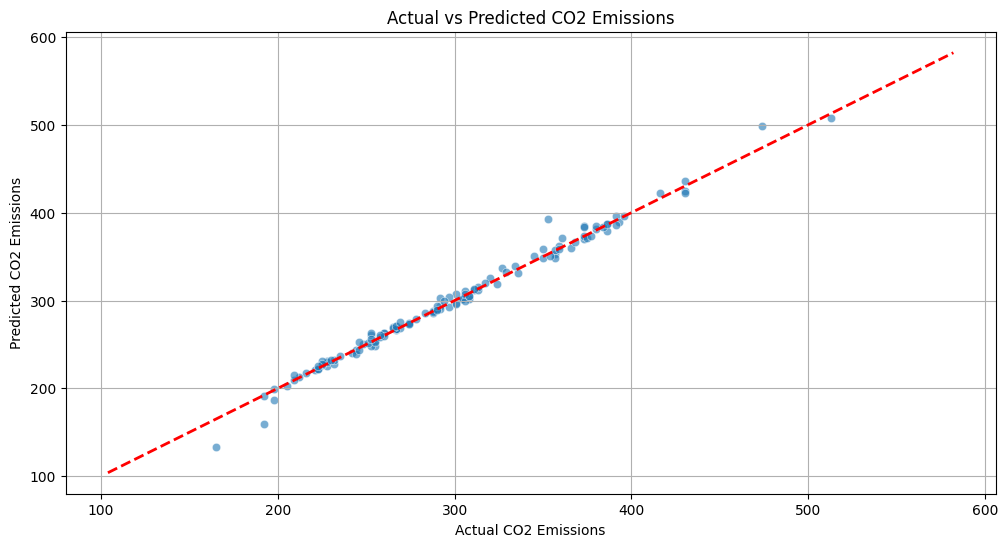

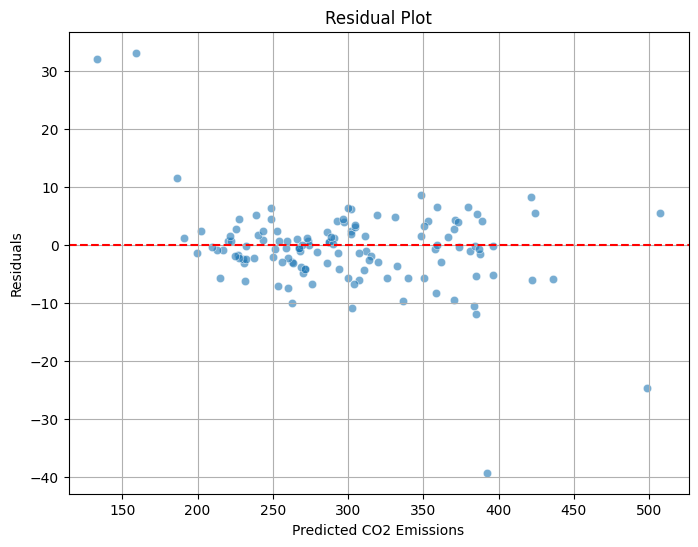

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Scatter plot of original data (Engine Size vs COEMISSIONS) and Regression Line
# For simplicity, we'll use 'ENGINE SIZE' as the primary feature for a 2D scatter plot if it exists and is numeric.
# If a simple 2D plot isn't representative, we'll note that.

plt.figure(figsize=(12, 6))

# Check if 'ENGINE SIZE' is directly in X_test (before one-hot encoding)
# If it's not, we might need to recreate a simplified df or choose another numeric feature.
if 'ENGINE SIZE' in X.columns:
    # Since X is already one-hot encoded, we can't directly plot 'ENGINE SIZE' against y_test if it was dropped
    # or transformed. Let's plot actual vs predicted for now, and then residuals.
    print("Cannot directly plot original 'ENGINE SIZE' vs 'COEMISSIONS' with regression line from one-hot encoded X.")
    print("Plotting Actual vs Predicted values instead.")
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
    plt.plot([y.min(), y.max()], [y.min(), y.max()], '--r', linewidth=2) # Line for perfect prediction
    plt.title('Actual vs Predicted CO2 Emissions')
    plt.xlabel('Actual CO2 Emissions')
    plt.ylabel('Predicted CO2 Emissions')
    plt.grid(True)
    plt.show()

    # Residual plot
    plt.figure(figsize=(8, 6))
    residuals = y_test - y_pred
    sns.scatterplot(x=y_pred, y=residuals, alpha=0.6)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.title('Residual Plot')
    plt.xlabel('Predicted CO2 Emissions')
    plt.ylabel('Residuals')
    plt.grid(True)
    plt.show()

else:
    print("Could not find 'ENGINE SIZE' in original features for a simple scatter plot. Plotting Actual vs Predicted.")
    # Actual vs Predicted plot
    sns.scatterplot(x=y_test, y=y_pred, alpha=0.6)
    plt.plot([y.min(), y.max()], [y.min(), y.max()], '--r', linewidth=2) # Line for perfect prediction
    plt.title('Actual vs Predicted CO2 Emissions')
    plt.xlabel('Actual CO2 Emissions')
    plt.ylabel('Predicted CO2 Emissions')
    plt.grid(True)
    plt.show()

